# Marketpele Feed: дизайн и анализ A/B-теста расположения платных и органических элементов

#### Данные
- `user_activity_data.csv` — исторические данные (дневная активность пользователей), используются для EDA и дизайна теста;
- `experiment_data.csv` — результаты эксперимента (агрегаты по пользователю за период теста + группа).

#### Структура
1. Предобработка данных
2. Исследовательский анализ (EDA)
3. Дизайн теста
4. Анализ результатов теста

#### Описание проекта
Список объявлений Marketpele содержит "органические" и "платные" элементы. Платные элементы - это рекламные объявления, при нажатии на них пользователи переходят на страницу рекламодателя и приносят доход Marketpele. Органические элементы - это контент издателя, при нажатии на них пользователи переходят на другую статью от того же издателя.

In [194]:
#Ипортируем библиотеки для анализа 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats import weightstats as stests

## 1. Предобработка данных

Датасет `user_activity_data.csv`:

• `Date` - дата

• `user_id` - идентификатор пользователя

• `Device` - тип устройства

• `pages_viewed` - количество просмотров страниц

• `paid_clicks` - количество кликов на рекламные объявления

• `organic_clicks` - количество кликов на органические ссылки

• `Revenue` - доход от действий пользователей

In [134]:
user_daily_data = pd.read_csv('user_activity_data.csv')  # Загрузка данных из CSV файла
user_daily_data.head()  # Просмотр первых нескольких строк данных

,date,user_id,device,pages_viewed,paid_clicks,organic_clicks,revenue
0,2026-01-01,1,mobile,18,6,0,11.30
1,2026-01-01,4,desktop,6,0,4,5.13
2,2026-01-01,6,desktop,6,2,0,3.89
3,2026-01-01,9,mobile,12,1,12,9.51
4,2026-01-01,11,mobile,15,3,7,13.69


In [135]:
user_daily_data.info()  # Получение информации о типах данных и пропущенных значениях

<class 'pandas.DataFrame'>
RangeIndex: 89353 entries, 0 to 89352
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            89353 non-null  str    
 1   user_id         89353 non-null  int64  
 2   device          89353 non-null  str    
 3   pages_viewed    89353 non-null  int64  
 4   paid_clicks     89353 non-null  int64  
 5   organic_clicks  89353 non-null  int64  
 6   revenue         89353 non-null  float64
dtypes: float64(1), int64(4), str(2)
memory usage: 4.8 MB


In [136]:
user_daily_data.isna().sum() # Проверка на наличие пропущенных значений в данных

date              0
user_id           0
device            0
pages_viewed      0
paid_clicks       0
organic_clicks    0
revenue           0
dtype: int64

In [137]:
user_daily_data['date'] = pd.to_datetime(user_daily_data['date'])  # Преобразование столбца 'date' в формат datetime

In [138]:
print(f"Количество уникальных пользователей после фильтрации: {user_daily_data['user_id'].nunique()}")  # Получение уникальных идентификаторов пользователей после фильтрации
print(f"Данные представлены за период с {user_daily_data['date'].min().date()} по {user_daily_data['date'].max().date()}")  # Получение диапазона дат в данных

Количество уникальных пользователей после фильтрации: 3000
Данные представлены за период с 2026-01-01 по 2026-02-25


In [139]:
dau = (user_daily_data.groupby('date')
        .agg(dau=('user_id', 'nunique')
        )
    ) #Группировка данных по дате с подсчетом уникальных пользователей, среднего количества просмотренных страниц и суммарного дохода

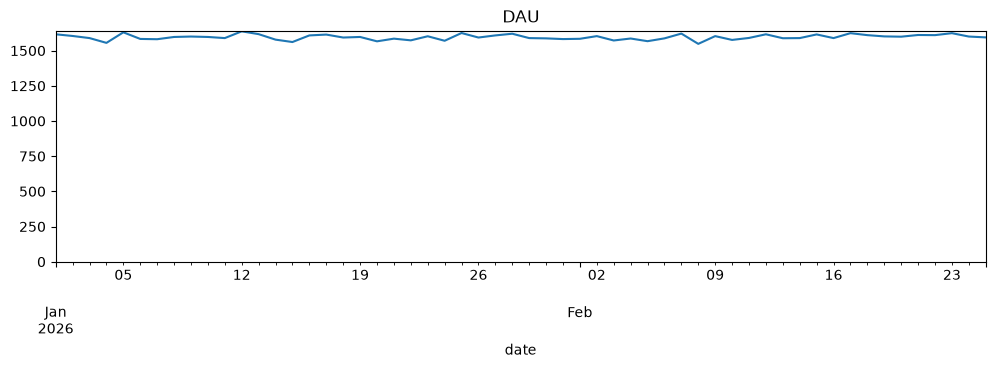

In [140]:
ax = dau["dau"].plot(figsize=(12, 3), title="DAU")
ax.set_ylim(bottom=0)

plt.show()

In [141]:
print(f"DAU среднее: {dau['dau'].mean():.0f}, медиана: {dau['dau'].median():.0f}, минимум: {dau['dau'].min():.0f}, максимум: {dau['dau'].max():.0f}")  # Вывод среднего и медианного значения DAU

DAU среднее: 1596, медиана: 1596, минимум: 1548, максимум: 1637


In [142]:
wau = (user_daily_data
        .groupby(user_daily_data['date'].dt.to_period('W'))
        .agg(wau=('user_id', 'nunique'))
    )

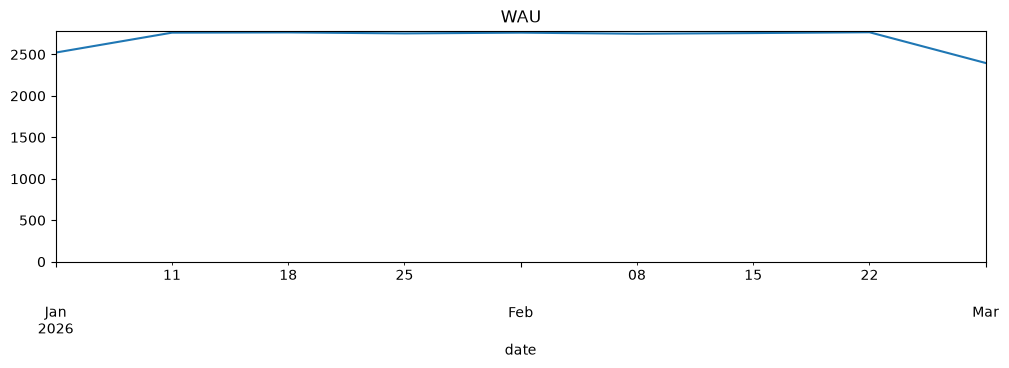

In [143]:
ax = wau["wau"].plot(figsize=(12, 3), title="WAU")
ax.set_ylim(bottom=0)

plt.show()

In [144]:
print(f"WAU среднее: {wau['wau'].mean():.0f}, медиана: {wau['wau'].median():.0f}, минимум: {wau['wau'].min():.0f}, максимум: {wau['wau'].max():.0f}")  # Вывод среднего и медианного значения WAU

WAU среднее: 2693, медиана: 2757, минимум: 2396, максимум: 2767


**Пропуски и тип данных**

Все строки датасета полностью заполнены, а типы данных соответствуют данным в них


### Группировка и обработка выбросов

In [145]:
users_data = user_daily_data.groupby(['user_id','device'], as_index=False).sum(numeric_only=True)  # Группировка данных по пользователям и устройствам
users_data.head()  # Просмотр первых нескольких строк сгруппированных данных

,user_id,device,pages_viewed,paid_clicks,organic_clicks,revenue
0,0,mobile,784,172,197,900.61
1,1,mobile,696,164,134,681.60
2,2,mobile,178,31,108,108.38
3,3,mobile,180,9,54,118.37
4,4,desktop,62,14,44,89.52


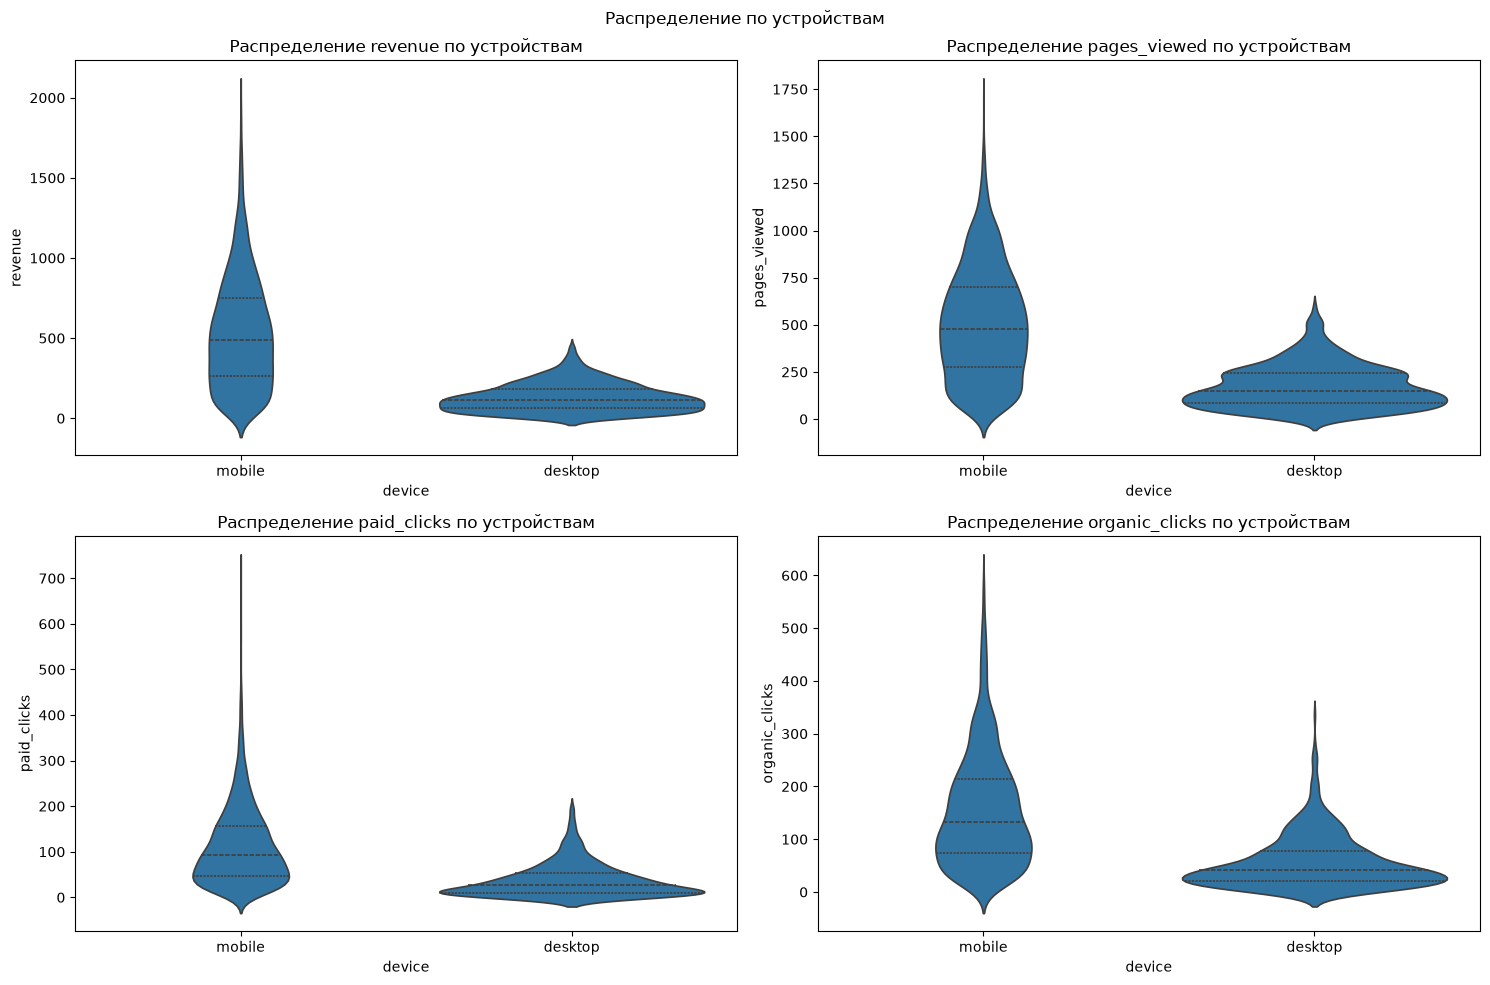

In [146]:
cols = ["revenue", "pages_viewed", "paid_clicks", "organic_clicks"] #Столбцы для построения violin plot

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, col in zip(axes.flat, cols):
    sns.violinplot(data=users_data, x="device", y=col, inner="quart", ax=ax)
    ax.set_title("Распределение " + col + " по устройствам")


fig.suptitle("Распределение по устройствам")   # общий заголовок
fig.tight_layout()                     # чтобы подписи не налезали друг на друга
plt.show()

Из графиков видна большая разница между пользователями desktop и mobile по всем метркиам, также видны выбросы у небольшой части пользователей. Отлфильтруем выббросы отдельно для mobile и desktop по методу 1,5IQR и оъеденим обратно.

In [147]:
users = users_data['user_id'].nunique()  # Получение уникальных идентификаторов пользователей до фильтрации
print(f"Количество уникальных пользователей до фильтрации: {users}")

users_data['device'].value_counts()  # Подсчет количества пользователей по устройствам

Количество уникальных пользователей до фильтрации: 3000


device
mobile     2379
desktop     621
Name: count, dtype: int64

In [148]:
users_data['device'].value_counts(normalize=True)  # Подсчет доли пользователей по устройствам

device
mobile     0.793
desktop    0.207
Name: proportion, dtype: float64

Каждый пользователь использует только одно устройство для входа на сайт. При этом почти 80% пользоватлей заходят с моильных устройств.

In [149]:
users_data_mob = users_data[users_data['device'] == 'mobile']  # Датасет только мобильных пользователй
users_data_desk = users_data[users_data['device'] == 'desktop']  # Датасет только десктопных пользователй

In [150]:
users_data_mob.describe()

,user_id,pages_viewed,paid_clicks,organic_clicks,revenue
count,2379.000000,2379.000000,2379.000000,2379.000000,2379.000000
mean,1512.827238,506.937369,111.813367,155.503993,532.426339
std,865.212655,292.927806,84.293584,106.511419,344.982347
min,0.000000,28.000000,1.000000,5.000000,28.170000
25%,767.500000,274.000000,47.000000,74.000000,260.615000
50%,1516.000000,480.000000,92.000000,133.000000,490.100000
75%,2261.500000,703.000000,156.000000,215.000000,750.360000
max,2999.000000,1684.000000,717.000000,595.000000,1975.570000


In [151]:
users_data_desk.describe()

,user_id,pages_viewed,paid_clicks,organic_clicks,revenue
count,621.000000,621.000000,621.000000,621.000000,621.000000
mean,1448.444444,174.115942,37.586151,56.634461,130.375008
std,868.633015,114.147878,36.500301,49.563840,87.615664
min,4.000000,5.000000,0.000000,0.000000,6.630000
25%,676.000000,85.000000,10.000000,21.000000,61.600000
50%,1422.000000,150.000000,26.000000,41.000000,115.390000
75%,2201.000000,245.000000,53.000000,78.000000,183.890000
max,2996.000000,590.000000,197.000000,335.000000,445.140000


In [152]:
def clen_data(df):
    q1, q3 = df[cols].quantile(0.25), df[cols].quantile(0.75)
    iqr = q3 - q1
    mask = ((df[cols] < q1 - 1.5 * iqr) | (df[cols] > q3 + 1.5 * iqr)).any(axis=1)

    return df[~mask]


In [153]:
cleaned_mob = clen_data(users_data_mob)  # Очистка данных мобильных пользователей от выбросов
cleaned_desk = clen_data(users_data_desk)  # Очистка данных десктопных пользователей от выбросов
cleaned_user_data = pd.concat([cleaned_mob, cleaned_desk])  # Объединение очищенных данных мобильных и десктопных пользователей

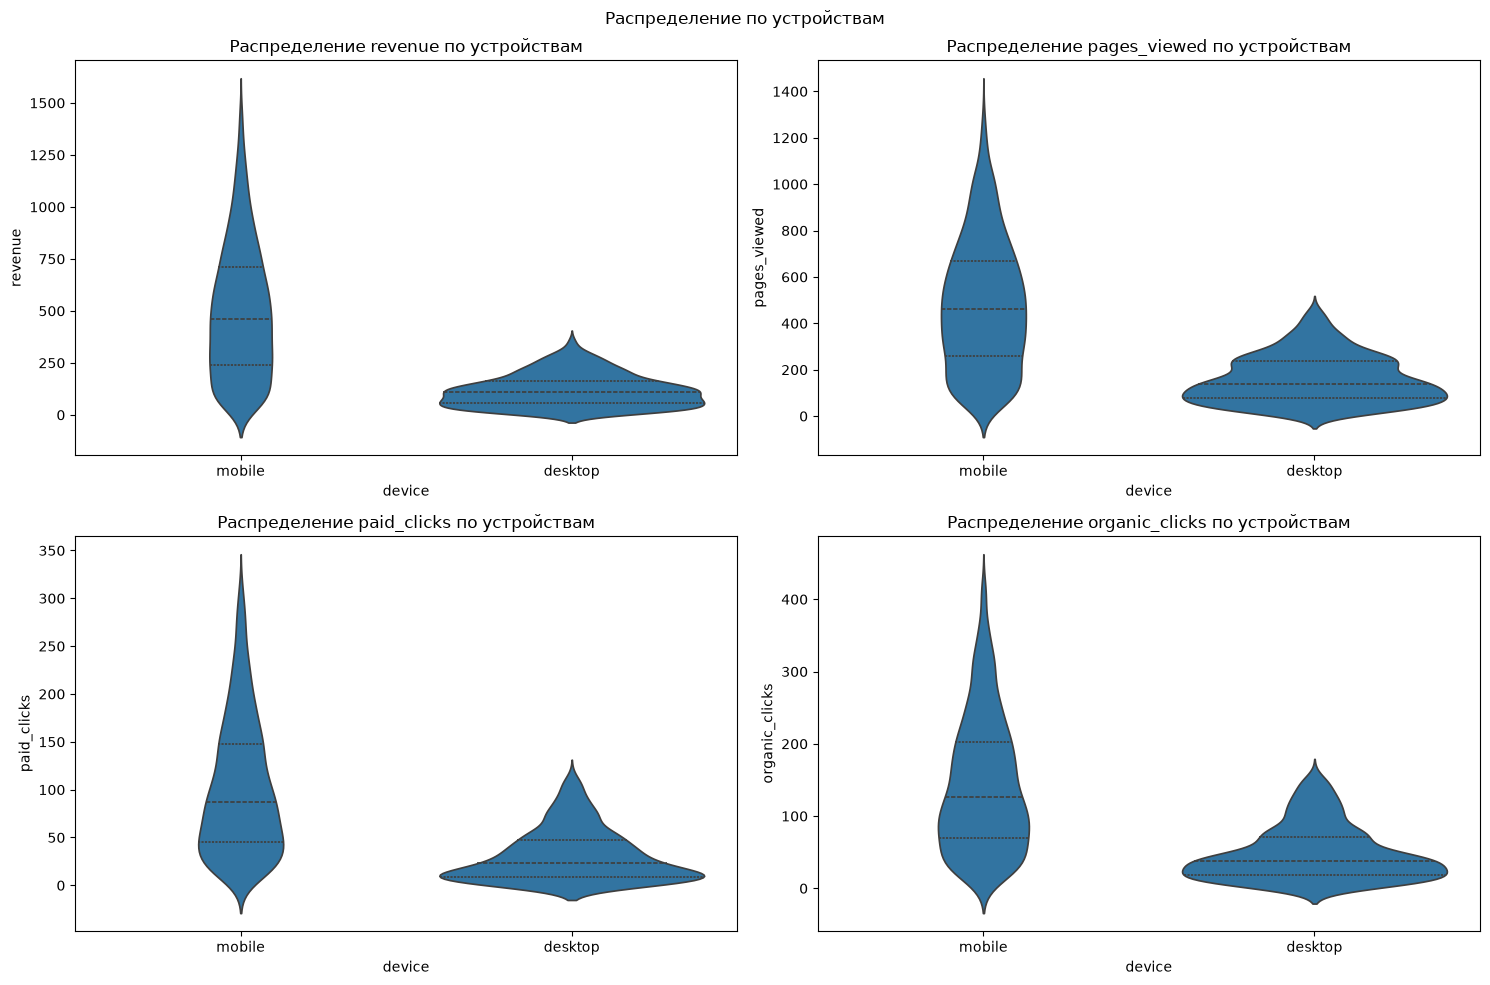

In [154]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, col in zip(axes.flat, cols):
    sns.violinplot(data=cleaned_user_data, x="device", y=col, inner="quart", ax=ax)
    ax.set_title("Распределение " + col + " по устройствам")


fig.suptitle("Распределение по устройствам")   # общий заголовок
fig.tight_layout()                     # чтобы подписи не налезали друг на друга
plt.show()

In [155]:
cleaned_mob.describe()  # Получение статистики по очищенным данным мобильных пользователей

,user_id,pages_viewed,paid_clicks,organic_clicks,revenue
count,2231.000000,2231.000000,2231.000000,2231.000000,2231.000000
mean,1516.682654,481.133572,102.158673,143.421784,499.534339
std,866.852153,276.946748,70.178714,91.831783,315.899986
min,0.000000,28.000000,1.000000,5.000000,28.170000
25%,764.000000,258.000000,45.000000,70.000000,240.150000
50%,1527.000000,461.000000,87.000000,126.000000,459.260000
75%,2267.500000,669.000000,148.000000,203.000000,709.360000
max,2999.000000,1338.000000,316.000000,423.000000,1483.290000


In [156]:
cleaned_desk.describe()  # Получение статистики по очищенным данным десктопных пользователей

,user_id,pages_viewed,paid_clicks,organic_clicks,revenue
count,554.000000,554.000000,554.000000,554.000000,554.000000
mean,1440.900722,159.866426,31.088448,48.357401,117.860090
std,866.021760,102.533460,27.038673,37.306638,77.316187
min,4.000000,5.000000,0.000000,0.000000,6.630000
25%,673.000000,77.000000,9.000000,19.000000,55.282500
50%,1416.500000,140.000000,23.000000,38.000000,108.240000
75%,2170.000000,236.500000,47.000000,71.000000,164.057500
max,2996.000000,460.000000,116.000000,158.000000,361.580000


В датасете присутствуют строки, а которых не было ни одного платного клика, но при этом есть revenue у пользователя. Если в датасете с разбивкой на даты это можно объяснить дотеканием данных из рекламной системы, то в сгруппированных данных это скорее указывает на ошибку отслеживания кликов по рекламным объявлениям. 

In [157]:
cleaned_user_data = cleaned_user_data[~(cleaned_user_data['paid_clicks'] == 0) & (cleaned_user_data['revenue'] > 0)]

In [158]:
print(f"Количество уникальных пользователей до фильтрации: {users_data['user_id'].nunique()}")  # Получение уникальных идентификаторов пользователей до фильтрации
print(f"Количество уникальных пользователей после фильтрации: {cleaned_user_data['user_id'].nunique()}")  # Получение уникальных идентификаторов пользователей после фильтрации
print(f"Удалено {users_data['user_id'].nunique() - cleaned_user_data['user_id'].nunique()} ({(users_data['user_id'].nunique() - cleaned_user_data['user_id'].nunique()) / users_data['user_id'].nunique() * 100:.1f}%) пользователей")  # Подсчет количества удаленных пользователей

Количество уникальных пользователей до фильтрации: 3000
Количество уникальных пользователей после фильтрации: 2775
Удалено 225 (7.5%) пользователей


### Добовляем CTR и считаем корреляции

In [159]:
cleaned_user_data['paid_ctr'] = cleaned_user_data['paid_clicks'] / cleaned_user_data['pages_viewed']  # Вычисление CTR для платных кликов
cleaned_user_data['organic_ctr'] = cleaned_user_data['organic_clicks'] / cleaned_user_data['pages_viewed']  # Вычисление CTR для органических кликов
cleaned_user_data['RPM'] = cleaned_user_data['revenue'] / cleaned_user_data['pages_viewed'] * 1000  # Вычисление RPM (Revenue Per Mille)

cleaned_user_data = cleaned_user_data.rename(columns={'revenue': 'ARPU'})

In [160]:
cleaned_user_data.describe()

,user_id,pages_viewed,paid_clicks,organic_clicks,ARPU,paid_ctr,organic_ctr,RPM
count,2775.000000,2775.000000,2775.000000,2775.000000,2775.000000,2775.000000,2775.000000,2775.000000
mean,1503.500180,418.532613,88.338378,124.900180,425.020040,0.224523,0.327749,1050.681581
std,866.897244,282.465489,69.892825,91.977265,322.746722,0.132584,0.179508,582.538001
min,0.000000,5.000000,1.000000,0.000000,7.060000,0.005780,0.000000,146.567506
25%,747.500000,177.500000,33.000000,49.000000,149.265000,0.133819,0.206518,669.970964
50%,1509.000000,370.000000,71.000000,104.000000,353.420000,0.201900,0.293463,913.545296
75%,2255.500000,613.500000,130.000000,183.000000,635.060000,0.288462,0.409209,1272.098249
max,2999.000000,1338.000000,316.000000,423.000000,1483.290000,1.600000,1.907407,7866.304348


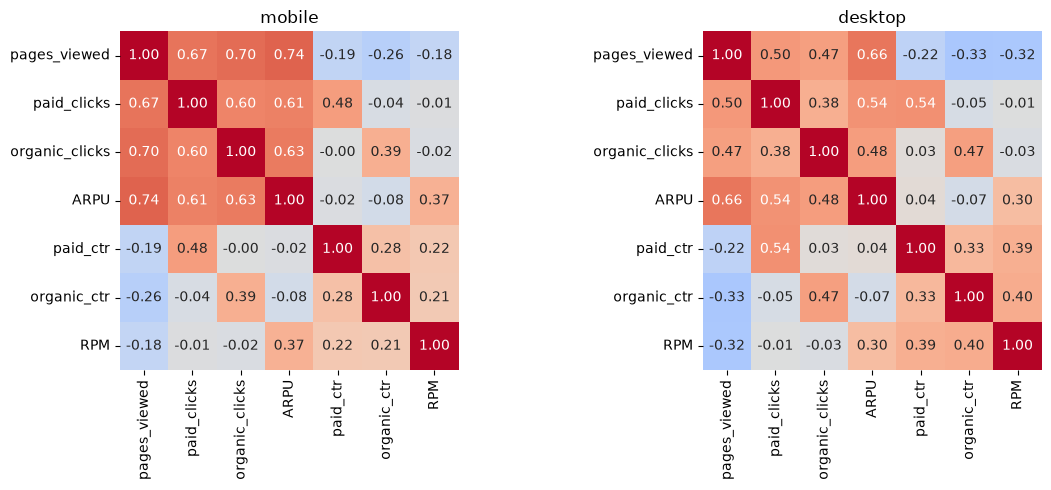

In [161]:
num_cols = cleaned_user_data.select_dtypes("number").columns.drop("user_id", errors="ignore")
devices = cleaned_user_data["device"].unique()

fig, axes = plt.subplots(1, len(devices), figsize=(6 * len(devices), 5))

for ax, device in zip(axes, devices):
    corr = cleaned_user_data.loc[cleaned_user_data["device"] == device, num_cols].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
                square=True, cbar=False, ax=ax)
    ax.set_title(device)

plt.tight_layout()
plt.show()

По карте корреляций видно, что у ARPU достаточно сиильная корреляция не только с paid_clicks, но и с pages_viewed и с organic_clicks, второе можно оъяснить общей тенденцией "Чем более активно пользователей взаимодействет с лентой, тем чаще он кликает на рекламу", прямая корреляция между paid и organic clicks подтверждает это и также говорит об отсутствии канибализации трафика. У пользователей desktop корреляция хуже.

При проведлении A/B-теста, ножно будет следить за метрикой pages_viewed, так как ее сильное снижение, может привести к более сильному падению ARPU, чем рост paid_clicks.

### Дизайн теста
Перенос четырех рекламных блоков с низу ленты рекомендаций на верх увеличит конверсию в клик по рекламному объявлению у всех пользователей платформы, а следовательно и ARPU на 6,5%, при этом мы ожмдаем снижения просмотров страниц не более чем на 10%.

Целевая метрика: ARPU
Прокси метрика: paid_ctr
guardrail: pages_viewed

**H0:** Средние сзначения ARPU равны.

**H1:** Средние сзначения ARPU не равны.

Альтернативная гипотеза двусторонняя, так как возможно и снижение ARPU в результате эксперимента.

#### Выираем уровень значимости и мощности теста


In [162]:
def mde_mean(std, n_a, n_b=None, alpha=0.05, power=0.8):
    n_b = n_b or n_a
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    return z * std * np.sqrt(1 / n_a + 1 / n_b)


def mde_by_weeks(data, metric, max_weeks=4, alpha=0.05, power=0.8, n_groups=2):
    start = data['date'].min()
    rows = []

    for weeks in range(1, max_weeks + 1):
        period = data[data['date'] < start + pd.Timedelta(weeks=weeks)]
        per_user = period.groupby('user_id')[metric].sum()      # метрика на пользователя за весь период

        n = per_user.size // n_groups
        mde = mde_mean(per_user.std(), n, alpha=alpha, power=power)

        rows.append({
            'weeks': weeks,
            'users_per_group': n,
            'mean': per_user.mean(),
            'std': per_user.std(),
            'mde_abs': mde,
            'mde_rel_%': mde / per_user.mean() * 100,
        })

    return pd.DataFrame(rows).set_index('weeks').round(3)


mde_by_weeks(user_daily_data, 'pages_viewed', max_weeks=4)


,users_per_group,mean,std,mde_abs,mde_rel_%
weeks,,,,,
1,1385,59.039,40.310,4.291,7.269
2,1458,112.630,78.012,8.095,7.187
3,1482,165.995,114.634,11.798,7.107
4,1494,219.791,152.145,15.596,7.096


In [163]:
def ratio_std(num, den):
    """Эквивалентный std на пользователя для метрики sum(num)/sum(den) (дельта-метод)."""
    mx, my = num.mean(), den.mean()
    var_x, var_y = num.var(), den.var()
    cov = np.cov(num, den)[0, 1]
    var_eff = var_x / my**2 - 2 * mx * cov / my**3 + mx**2 * var_y / my**4
    return np.sqrt(var_eff)


def mde_ratio_by_weeks(data, num_col, den_col, max_weeks=4, alpha=0.05, power=0.74, n_groups=2):
    start = data['date'].min()
    rows = []

    for weeks in range(1, max_weeks + 1):
        period = data[data['date'] < start + pd.Timedelta(weeks=weeks)]
        per_user = period.groupby('user_id')[[num_col, den_col]].sum()
        per_user = per_user[per_user[den_col] > 0]              # пользователи без показов в CTR не участвуют

        n = len(per_user) // n_groups
        ctr = per_user[num_col].sum() / per_user[den_col].sum()
        std = ratio_std(per_user[num_col], per_user[den_col])
        mde = mde_mean(std, n, alpha=alpha, power=power)

        rows.append({
            'weeks': weeks,
            'users_per_group': n,
            'ctr': ctr,
            'mde_abs': mde,
            'mde_rel_%': mde / ctr * 100,
        })

    return pd.DataFrame(rows).set_index('weeks').round(4)


mde_ratio_by_weeks(user_daily_data, num_col='paid_clicks', den_col='pages_viewed')

,users_per_group,ctr,mde_abs,mde_rel_%
weeks,,,,
1,1385,0.2199,0.0155,7.0469
2,1458,0.2208,0.0143,6.4716
3,1482,0.2201,0.0136,6.1935
4,1494,0.2200,0.0133,6.0565


| Метрика   | 2 недели | 3 недели | 4 недели |
|-----------|----------|----------|----------|
| ARPU      | 10.780%     | 9.629%     | 9.082%     |
| paid_ctr  | 6.965%    | 6.665%    | 6.518%    |
| pages_viewed  | 7.187%    | 7.107%    | 7.096%    |

ARPU не проходит по желаемому изменению. Проверим какая мощность теста соответствует 6,5%. 

100%|██████████| 1000/1000 [00:03<00:00, 276.12it/s]


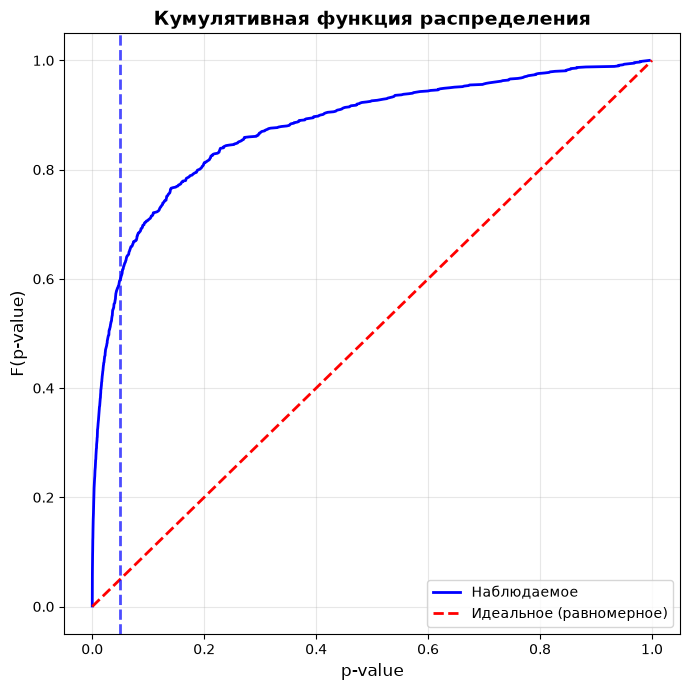

power = 0.598


In [164]:
# Функция для построения распределения p_value
def draw_cdf_plot(p_values, alpha):
    sorted_p = np.sort(p_values)
    cdf = np.arange(1, len(sorted_p) + 1) / len(sorted_p)

    plt.figure(figsize=(7, 7))
    plt.plot(sorted_p, cdf, 'b-', linewidth=2, label='Наблюдаемое')
    plt.plot([0, 1], [0, 1], 'r--', linewidth=2, label='Идеальное (равномерное)')
    plt.xlabel('p-value', fontsize=12)
    plt.ylabel('F(p-value)', fontsize=12)
    plt.title('Кумулятивная функция распределения', fontsize=14, fontweight='bold')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.axvline(x=alpha, 
           color='blue', 
           linestyle='--', 
           alpha=0.7, 
           linewidth=2)

    # Вычисляем FPR (False Positive Rate)
    fpr_05 = np.mean(np.array(sorted_p) <= alpha)

    plt.tight_layout()
    plt.show()

    print(f'power = {fpr_05}')

from tqdm import tqdm

# Проводим 1000 A/B-тестов для проверки распределения p-value
n_simulations = 1000
p_values = []
effect = 1.065

for i in tqdm(range(n_simulations)):
    # Случайное разделение
    temp_data = cleaned_user_data.copy()
    temp_data['group'] = np.random.choice(['A', 'B'], size=len(temp_data), p=[0.5, 0.5])
    
    group_a_temp = temp_data.copy()[temp_data['group'] == 'A']
    group_b_temp = temp_data.copy()[temp_data['group'] == 'B']
    
    group_b_temp['ARPU_effected'] = group_b_temp['ARPU'] * effect
    
    # Тест
    t_stat_temp, p_rev_temp = stats.ttest_ind(
        group_a_temp['ARPU'], 
        group_b_temp['ARPU_effected']
    )
    p_values.append(p_rev_temp)

draw_cdf_plot(p_values, 0.05)

6.5% соответствует мощность 60%, что недостаточно. Попробуем повысить мощность теста за счет CUPED метрики, так как увеличение длительности теста не дает значимого прироста.

In [165]:
def compute_theta(df_control, df_pilot):
    """
    Вычисляет theta по объединённым данным контрольной и тестовой групп.
    """
    X_all = np.concatenate([df_control['metric_before'].values, df_pilot['metric_before'].values])
    Y_all = np.concatenate([df_control['metric'].values, df_pilot['metric'].values])
    
    cov_xy = np.cov(X_all, Y_all)[0, 1]
    var_x = np.var(X_all)
    
    return cov_xy / var_x if var_x > 0 else 0.0

def apply_cuped(df, theta):
    """
    Применяет CUPED без центрирования.
    """
    return df['metric'].values - theta * df['metric_before'].values

def check_test(df_control, df_pilot, covariate_col='metric_before'):
    """
    CUPED t-test: сначала корректируем метрику, потом t-test.
    """
    # Вычисляем theta по объединённым данным
    theta = compute_theta(df_control, df_pilot)
    
    # Применяем CUPED к каждой группе
    metric_control_cv = apply_cuped(df_control, theta)
    metric_pilot_cv = apply_cuped(df_pilot, theta)
    
    # t-test на скорректированных метриках
    _, p_value = stats.ttest_ind(metric_control_cv, metric_pilot_cv, equal_var=False)
    return p_value

In [166]:
daily = user_daily_data
start = daily['date'].min()

PRE_DAYS, TEST_DAYS = 28, 28
test_start = start + pd.Timedelta(days=PRE_DAYS)
test_end = test_start + pd.Timedelta(days=TEST_DAYS)

pre = (daily[daily['date'] < test_start]
       .groupby('user_id')['revenue'].sum().rename('metric_before'))

during = (daily[(daily['date'] >= test_start) & (daily['date'] < test_end)]
          .groupby('user_id')['revenue'].sum().rename('metric'))

users = pd.concat([during, pre], axis=1, join='inner')

In [209]:
rng = np.random.default_rng(42)

def split_groups(users, effect=0.0):
    is_pilot = rng.random(len(users)) < 0.5
    control = users[~is_pilot]
    pilot = users[is_pilot].copy()
    pilot['metric'] *= 1 + effect          # effect=0.065 значит +6,5% к ARPU в тестовой группе
    return control, pilot

df_control, df_pilot = split_groups(users, effect=0.065)
print(check_test(df_control, df_pilot))

0.09734823759428517


In [210]:
def simulate(users, effect=0.0, n_iter=1000, alpha=0.05):
    hits_ttest, hits_cuped = 0, 0
    for _ in range(n_iter):
        c, p = split_groups(users, effect)
        hits_ttest += stats.ttest_ind(c['metric'], p['metric'], equal_var=False).pvalue < alpha
        hits_cuped += check_test(c, p) < alpha
    return hits_ttest / n_iter, hits_cuped / n_iter

aa = simulate(users, effect=0.0)    # A/A: доля ложных срабатываний, должна быть около 0.05
ab = simulate(users, effect=0.065)   # A/B: мощность (доля пойманных эффектов)

pd.DataFrame({'A/A (FPR)': aa, 'A/B +6.5% (power)': ab}, index=['t-test', 'CUPED'])

,A/A (FPR),A/B +6.5% (power)
t-test,0.039,0.547
CUPED,0.046,0.740


Удалось поднять мощность теста до 74%

Итоговый дизайн:
Длительность - 3 недели
Трафик - 100%, сплит 50/50.
MDE - ARPU - 6.5%, CTR - 6.5%, page_views - 7%
CUPED используем для ARPU
Выбросы отрабатываем по 1,5IQR отдельно по устройствам.
Мощность - 74%
альфа - 5%

Правило решения: раскатываем, если ARPU значимо вырос, а просмотры значимо не упали.

### Анализ результатов теста

In [183]:
ab_result = pd.read_csv('experiment_data.csv')
ab_result.head()
ab_result.drop_duplicates('user_id')

,user_id,pages_viewed,paid_clicks,organic_clicks,revenue,device,ctr_paid,ctr_organic,group
0,1,61,15,10,35.06,mobile,0.245902,0.163934,control
1,2,213,57,114,179.21,mobile,0.267606,0.535211,control
2,5,23,3,13,13.75,desktop,0.130435,0.565217,control
3,8,356,30,182,271.25,mobile,0.084270,0.511236,control
4,9,226,25,45,418.44,mobile,0.110619,0.199115,control
...,...,...,...,...,...,...,...,...,...
1978,1986,140,62,55,119.84,mobile,0.492108,0.304406,test
1979,1989,120,59,48,156.06,mobile,0.558156,0.305039,test
1980,1991,167,53,48,115.35,desktop,0.366346,0.218718,test
1981,1992,277,21,68,162.51,mobile,0.084926,0.174790,test


In [184]:
print(f'Пользователей в тесте: {ab_result["user_id"].nunique()}')
print(f'В группе А: {ab_result[ab_result["group"] == "control"]["user_id"].nunique()}')
print(f'В группе Б: {ab_result[ab_result["group"] == "test"]["user_id"].nunique()}')

Пользователей в тесте: 1983
В группе А: 998
В группе Б: 985


Группа А и Б примерно равны по количеству пользователей (разница 1.3%)

In [185]:
pd.crosstab(ab_result['group'], ab_result['device'], normalize='index').mul(100).round(2)

device,desktop,mobile
group,,
control,20.64,79.36
test,22.13,77.87


In [186]:
counts = pd.crosstab(ab_result['group'], ab_result['device'])
chi2, p, _, _ = stats.chi2_contingency(counts)
print(f"p-value = {p:.4f}")

p-value = 0.4504


In [203]:
PRE_DAYS = 28   # как в дизайне

pre = (user_daily_data[user_daily_data['date'] > user_daily_data['date'].max() - pd.Timedelta(days=PRE_DAYS)]
       .groupby('user_id')[['revenue', 'pages_viewed', 'paid_clicks']].sum()
       .add_prefix('pre_'))

ab_result = ab_result.merge(pre, left_on='user_id', right_index=True, how='left')
ab_result[pre.columns] = ab_result[pre.columns].fillna(0)
ab_result['is_mobile'] = (ab_result['device'] == 'mobile').astype(int)

In [220]:
ALPHA = 0.05

def cuped_t_test(df, metric, covs, alpha=ALPHA):
    """CUPED + t-критерий Уэлча (scipy.stats.ttest_ind)."""
    X = df[covs].values - df[covs].values.mean(axis=0)
    y = df[metric].values
    theta, *_ = np.linalg.lstsq(X, y - y.mean(), rcond=None)   # theta по объединённым группам
    y_cuped = pd.Series(y - X @ theta, index=df.index)

    is_test = df['group'] == 'test'
    res = stats.ttest_ind(y_cuped[is_test], y_cuped[~is_test], equal_var=False)
    ci = res.confidence_interval(confidence_level=1 - alpha)
    base = df.loc[~is_test, metric].mean()                     # ARPU контроля без корректировки
    diff = y_cuped[is_test].mean() - y_cuped[~is_test].mean()

    return {
        'method': f'CUPED t-test ({", ".join(covs)})',
        'control': base,
        'test': base + diff,
        'effect_abs': diff,
        'effect_rel_%': diff / base * 100,
        'ci_low_%': ci.low / base * 100,
        'ci_high_%': ci.high / base * 100,
        'stat': res.statistic,
        'p_value': res.pvalue,
    }


def t_test_metric(df, metric, alpha=ALPHA):
    """t-критерий Уэлча (scipy.stats.ttest_ind) для среднего на пользователя."""
    t = df.loc[df['group'] == 'test', metric]
    c = df.loc[df['group'] == 'control', metric]

    res = stats.ttest_ind(t, c, equal_var=False)
    ci = res.confidence_interval(confidence_level=1 - alpha)   # ДИ разницы средних (test - control)
    base = c.mean()

    return {
        'method': 't-test (scipy)',
        'control': base,
        'test': t.mean(),
        'effect_abs': t.mean() - base,
        'effect_rel_%': (t.mean() / base - 1) * 100,
        'ci_low_%': ci.low / base * 100,
        'ci_high_%': ci.high / base * 100,
        'stat': res.statistic,
        'p_value': res.pvalue,
    }


def z_test_metric(df, metric, alpha=ALPHA):
    """Z-критерий (statsmodels ztest) для среднего на пользователя."""
    t = df.loc[df['group'] == 'test', metric]
    c = df.loc[df['group'] == 'control', metric]

    z_stat, p_value = stests.ztest(t, c)
    ci_low, ci_high = stests.zconfint(t, c, alpha=alpha)
    base = c.mean()

    return {
        'method': 'Z-test (statsmodels)',
        'control': base,
        'test': t.mean(),
        'effect_abs': t.mean() - base,
        'effect_rel_%': (t.mean() / base - 1) * 100,
        'ci_low_%': ci_low / base * 100,
        'ci_high_%': ci_high / base * 100,
        'stat': z_stat,
        'p_value': p_value,
    }


results_mob = pd.DataFrame({
    'ARPU':         cuped_t_test(ab_result[ab_result['device'] == 'mobile'], 'revenue', ['pre_revenue']),
    'paid_ctr':     z_test_metric(ab_result[ab_result['device'] == 'mobile'], 'ctr_paid'),
    'pages_viewed': t_test_metric(ab_result[ab_result['device'] == 'mobile'], 'pages_viewed'),
    'ctr_organic':     z_test_metric(ab_result[ab_result['device'] == 'mobile'], 'ctr_organic'),
}).T
results_mob['significant'] = results_mob['p_value'] < ALPHA
results_mob.round(4)

,method,control,test,effect_abs,effect_rel_%,ci_low_%,ci_high_%,stat,p_value,significant
ARPU,CUPED t-test (pre_revenue),205.402677,208.574053,3.171376,1.54398,-6.384197,9.472157,0.381992,0.702519,False
paid_ctr,Z-test (statsmodels),0.234783,0.269219,0.034436,14.667085,8.414945,20.919224,4.597939,0.000004,True
pages_viewed,t-test (scipy),195.127525,200.065189,4.937664,2.53048,-3.507449,8.56841,0.822059,0.41117,False
ctr_organic,Z-test (statsmodels),0.343124,0.245849,-0.097275,-28.349709,-33.320759,-23.378659,-11.1776,0.0,True


In [221]:
results_desk = pd.DataFrame({
    'ARPU':         cuped_t_test(ab_result[ab_result['device'] == 'desktop'], 'revenue', ['pre_revenue']),
    'paid_ctr':     z_test_metric(ab_result[ab_result['device'] == 'desktop'], 'ctr_paid'),
    'pages_viewed': t_test_metric(ab_result[ab_result['device'] == 'desktop'], 'pages_viewed'),
    'ctr_organic':     z_test_metric(ab_result[ab_result['device'] == 'desktop'], 'ctr_organic'),
}).T
results_desk['significant'] = results_desk['p_value'] < ALPHA
results_desk.round(4)

,method,control,test,effect_abs,effect_rel_%,ci_low_%,ci_high_%,stat,p_value,significant
ARPU,CUPED t-test (pre_revenue),51.093981,52.982567,1.888587,3.6963,-12.456242,19.848842,0.449823,0.653073,False
paid_ctr,Z-test (statsmodels),0.243319,0.291311,0.047991,19.723568,0.174132,39.273004,1.977422,0.047994,True
pages_viewed,t-test (scipy),72.718447,68.573394,-4.145052,-5.700138,-18.672212,7.271935,-0.863717,0.388234,False
ctr_organic,Z-test (statsmodels),0.357025,0.311527,-0.045498,-12.743682,-28.238869,2.751505,-1.61193,0.106977,False


In [222]:
results = pd.DataFrame({
    'ARPU':         cuped_t_test(ab_result, 'revenue', ['pre_revenue']),
    'paid_ctr':     z_test_metric(ab_result, 'ctr_paid'),
    'pages_viewed': t_test_metric(ab_result, 'pages_viewed'),
    'ctr_organic':     z_test_metric(ab_result, 'ctr_organic'),
}).T
results['significant'] = results['p_value'] < ALPHA
results.round(4)

,method,control,test,effect_abs,effect_rel_%,ci_low_%,ci_high_%,stat,p_value,significant
ARPU,CUPED t-test (pre_revenue),173.551383,175.681567,2.130184,1.227408,-6.775251,9.230068,0.300793,0.763604,False
paid_ctr,Z-test (statsmodels),0.236545,0.274108,0.037563,15.879921,9.379042,22.3808,4.787671,0.000002,True
pages_viewed,t-test (scipy),169.860721,170.963452,1.10273,0.649197,-5.547874,6.846267,0.205449,0.837242,False
ctr_organic,Z-test (statsmodels),0.345993,0.260385,-0.085608,-24.742748,-29.929216,-19.556279,-9.350273,0.0,True


In [223]:
def forest_plot(res, main=None, separator_before=None, figsize=(10, 4)):
    INK, MUTED, GRID = '#1b2238', '#6b7280', '#d9d9d9'
    BLUE, ORANGE = '#2f7bd8', '#e0602a'

    res = res.copy()
    num_cols = ['effect_rel_%', 'ci_low_%', 'ci_high_%', 'p_value']
    res[num_cols] = res[num_cols].astype(float)
    n = len(res)
    y = np.arange(n)[::-1]                                  # первая строка таблицы — сверху

    fig, ax = plt.subplots(figsize=figsize)

    for yi, (name, r) in zip(y, res.iterrows()):
        color = ORANGE if r['significant'] else BLUE
        ax.plot([r['ci_low_%'], r['ci_high_%']], [yi, yi], color=color, lw=4,
                solid_capstyle='round', zorder=2)
        ax.scatter(r['effect_rel_%'], yi, s=160, color=color, edgecolor='white', linewidth=2, zorder=3)

        eff = f"{r['effect_rel_%']:+.1f}%".replace('-', '−')
        text = f"{eff} · значимо" if r['significant'] else f"{eff} · p = {r['p_value']:.2f}"
        weight = 'bold' if name == main or r['significant'] else 'normal'
        ax.annotate(text, xy=(1.02, yi), xycoords=('axes fraction', 'data'), va='center',
                    fontsize=12, color=ORANGE if r['significant'] else INK, fontweight=weight)

    ax.set_yticks(y)
    ax.set_yticklabels(res.index, fontsize=12, color=INK)
    for lbl in ax.get_yticklabels():
        if lbl.get_text() == main:
            lbl.set_fontweight('bold')

    lim = np.ceil(max(res['ci_high_%'].abs().max(), res['ci_low_%'].abs().max()) / 10) * 10 + 5
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-0.7, n - 0.3)
    ticks = np.arange(-lim + 5, lim, 10)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'{t:+.0f}%'.replace('-', '−') if t else '0' for t in ticks],
                       fontsize=11, color=MUTED)

    ax.axvline(0, color=INK, lw=1.5, zorder=1)
    ax.grid(axis='x', color=GRID, lw=1)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

    if separator_before is not None:
        ys = y[list(res.index).index(separator_before)] + 0.5
        ax.axhline(ys, color='#9ca3af', ls='--', lw=1)

    plt.tight_layout()
    plt.show()

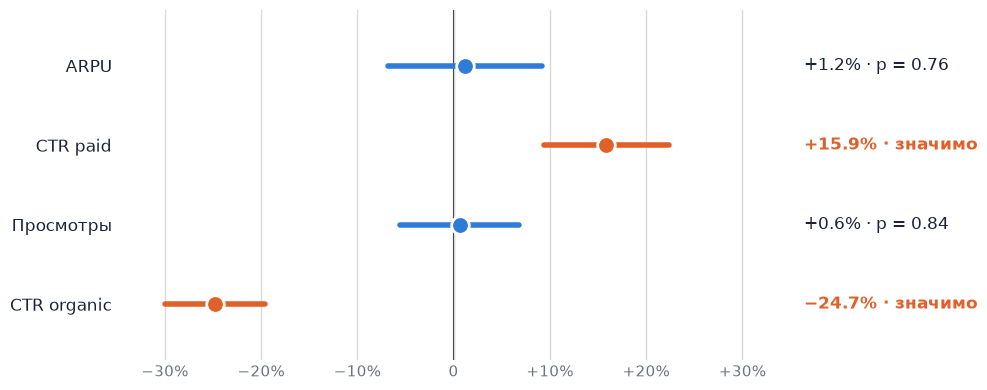

In [225]:
plot_df = results.rename(index={    'paid_ctr': 'CTR paid',
                                    'pages_viewed': 'Просмотры',
                                    'ctr_organic': 'CTR organic'})

forest_plot(plot_df, main='ARPU — главная')

## Выводы

**Корректность теста.** Группы сбалансированы: размеры 998 / 985, доля mobile/desktop одинаковая (p = 0.45). Результатам рандомизации можно доверять.

**1. Целевая метрика — ARPU: значимых изменений нет.**
ARPU в тестовой группе выше на +2.1% (CUPED, t-тест Уэлча), p = 0.57. Доверительный интервал включает ноль, H0 не отвергается.
Ожидаемый эффект +6.5% тоже попадает в интервал, поэтому тест не подтверждает гипотезу, но и не опровергает её полностью.

**2. CTR рекламы значимо вырос, CTR органики значимо упал.**
- paid CTR: **+16.8%** (значимо);
- organic CTR: **−26.8%** (значимо).
Механизм гипотезы сработал: после переноса рекламных блоков наверх по ним кликают чаще. Но рост платных кликов произошёл в основном за счёт органических: суммарная кликабельность ленты снизилась. Вывод EDA об отсутствии каннибализации в тесте не подтвердился.


**3. Рост кликов не превратился в выручку.**
Платных кликов стало больше, а ARPU не изменился, значит выручка на один клик снизилась. Вероятные причины: более низкое качество кликов (случайные клики в верхней части ленты) или более низкая стоимость рекламных слотов наверху.

**4. Guardrail — просмотры страниц: в норме.**
pages_viewed: +2.0%, p = 0.49. Нижняя граница интервала выше допустимого порога −10%, ограничивающая метрика не нарушена.

**5. Срезы mobile / desktop** значимых различий по ARPU не показывают. 

## Рекомендации

1. **Не раскатывать изменение.** Целевая метрика значимо не выросла, а падение органических кликов на ~27% — крупный негативный эффект. Его долгосрочное влияние на вовлечённость и удержание за время теста оценить нельзя.
2. **Разобрать экономику клика.** Сравнить стоимость клика и конверсию у рекламодателей для верхних и нижних слотов. Без этого рост CTR не приведёт к росту выручки.
3. **Добавить organic CTR в guardrail-метрики** следующих тестов изменения ленты.
4. **Протестировать менее агрессивный вариант:** 1–2 рекламных блока наверху вместо четырёх, чтобы найти баланс между платными и органическими кликами.
5. **Повторный тест рассчитать на нужную мощность.** Чтобы надёжно поймать +6.5% ARPU, нужно примерно в 2.5–3 раза больше пользователей.
